# 01 — Exploración de datos: NVDA y SPY a 1 minuto (6–13 nov 2026)

**Proyecto:** Path-Integral Quench Shock — réplica predictiva de Paolinelli & Arioli (2018),
*"A path integral based model for stocks and order dynamics"*, Physica A.

**Pregunta de este notebook:** antes del evento del 12 de noviembre de 2026 (renuncia de
Jensen Huang como CEO, según el planteamiento del proyecto), ¿los retornos de 1 minuto de NVDA ya
mostraban **colas gruesas**, es decir, más eventos extremos de los que predice una gaussiana?

Esto importa para el resto del proyecto: el modelo de Paolinelli–Arioli solo puede "anticipar" un
salto si la dinámica previa contiene curtosis en exceso que una perturbación por órdenes
($\alpha_1, \alpha_2$) pueda capturar. Si los datos previos son gaussianos, el modelo calibrado
colapsará al GBM.

**Ventanas temporales (hora de Nueva York):**

| Ventana | Rango | Uso |
|---|---|---|
| Pre-evento (calibración) | 6 nov 04:00 → 11 nov 16:00 (cierre regular) | Única ventana válida para calibrar (notebook 03) |
| Evento | 11 nov 16:00 → 12 nov 20:00 | Nunca se usa para calibrar |
| Post-evento | 13 nov | Solo como contexto |

> **Nota:** el notebook no usa datos inventados. Todo lo que se reporta sale de los CSV de
> `data/raw/yahoo_1m/`, y los días faltantes se informan explícitamente.

## 1. Configuración

Se localiza la raíz del proyecto subiendo desde el directorio de trabajo hasta encontrar `src/`.
Así el notebook funciona tanto si se abre desde `notebooks/` como desde la raíz. Se fija la
semilla (`np.random.seed(42)`) para que el bootstrap de la sección 6 sea reproducible.

In [1]:
import logging
import sys
import warnings
from datetime import date, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from scipy import stats

def encontrar_raiz(inicio: Path) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "src" / "data_loader.py").exists():
            return p
    raise FileNotFoundError("No se encontró la raíz del proyecto (carpeta con src/data_loader.py)")

ROOT = encontrar_raiz(Path.cwd().resolve())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_loader import cargar_rango, NY_TZ
from src.returns import retornos_1m

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", force=True)
warnings.filterwarnings("ignore", category=FutureWarning)

np.random.seed(42)
RNG = np.random.default_rng(42)

FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TICKERS = ["NVDA", "SPY"]
DESDE, HASTA = date(2026, 11, 6), date(2026, 11, 13)
FECHA_EVENTO = date(2026, 11, 12)
FIN_CALIBRACION = pd.Timestamp("2026-11-11 16:00", tz=NY_TZ)   # excluido: última barra válida = 15:59
FIN_EVENTO = pd.Timestamp("2026-11-12 20:00", tz=NY_TZ)
SESIONES = ["Pre-market", "Regular", "After-hours"]
COLORES = {"Pre-market": "#4C78A8", "Regular": "#F58518", "After-hours": "#54A24B"}

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:,.6g}")

def guardar(fig, nombre: str) -> None:
    ruta = FIG_DIR / f"{nombre}.png"
    fig.savefig(ruta, bbox_inches="tight")
    print(f"Figura guardada: {ruta.relative_to(ROOT)}")

print("Raíz del proyecto:", ROOT)

Raíz del proyecto: D:\Proyectos Quants\Research-Finance\Path-Integral Quench Shock


## 2. Carga de datos e inventario

`cargar_rango` (en `src/data_loader.py`) lee un CSV por día, omite los fines de semana y
**avisa sin detenerse** si falta un día hábil o un archivo está vacío. Además normaliza los CSV
antiguos de SPY, que no traen `Adj Close` y tienen las columnas en otro orden.

Un día completo tiene 330 minutos de pre-market, 390 de sesión regular y 240 de after-hours.
Yahoo **omite los minutos sin operaciones**, así que la cobertura mide la liquidez de cada sesión.

In [2]:
datos = {t: cargar_rango(t, DESDE, HASTA) for t in TICKERS}

ESPERADO = {"Pre-market": 330, "Regular": 390, "After-hours": 240}
filas = []
for t, df in datos.items():
    dias_habiles = pd.bdate_range(DESDE, HASTA).date
    for d in dias_habiles:
        sub = df[df["Fecha"] == d]
        fila = {"Ticker": t, "Fecha": d, "Barras": len(sub)}
        if sub.empty:
            fila["Nota"] = "SIN DATOS"
        else:
            for s in SESIONES:
                fila[f"{s} (%)"] = 100 * (sub["Sesion"] == s).sum() / ESPERADO[s]
            fila["Primera"] = sub.index.min().strftime("%H:%M")
            fila["Última"] = sub.index.max().strftime("%H:%M")
            fila["Fuera de sesión"] = int((sub["Sesion"] == "Fuera de sesión").sum())
            fila["Nota"] = ""
        filas.append(fila)
inventario = pd.DataFrame(filas).set_index(["Ticker", "Fecha"])
inventario.style.format(precision=1)

**Lectura del inventario.**

- **Sesión regular:** está completa en todos los días (390/390 minutos).
- **NVDA, 11 nov:** el pre-market empieza a las 05:20 en lugar de a las 04:00, así que faltan
  80 minutos.
- **SPY, horario extendido:** tiene entre 85 % y 95 % de cobertura porque es menos líquido que NVDA
  fuera de la sesión regular.
- **Barra "Fuera de sesión" a las 20:00:** es un artefacto de Yahoo y se descarta en el análisis.

## 3. Retornos logarítmicos de 1 minuto

Se usa el retorno logarítmico

$$ r_t = \ln\frac{C_t}{C_{t-1}}, $$

que es la variable natural del modelo: con $x = \ln S$, el GBM es un proceso de difusión
gaussiano en $x$.

**Reglas de construcción (para no contaminar la distribución):**

1. Solo se toman **pares de minutos consecutivos** ($\Delta t = 1$ min). Si hay un hueco (un minuto
   sin operaciones), ese retorno se descarta en lugar de tratarlo como un retorno de 1 minuto, lo
   que inflaría artificialmente las colas.
2. Nunca se cruzan días: el *gap* overnight no es un retorno de 1 minuto.
3. Cada retorno se asigna a la sesión de la barra $t$ y se descartan las barras "Fuera de sesión".
4. Se separan los períodos **pre-evento**, **evento** y **post-evento** según las ventanas de la
   introducción.

Además se reporta la **fracción de retornos exactamente cero**. Un precio "congelado" (sin cambio
entre minutos) en horario extendido produce un pico en 0 que, por sí solo, eleva la curtosis.

La función `retornos_1m` está en `src/returns.py` para que los notebooks 03 y 04 usen
exactamente la misma construcción.

In [3]:
def asignar_periodo(r: pd.DataFrame) -> pd.DataFrame:
    r = r.copy()
    r["Periodo"] = np.select([r.index < FIN_CALIBRACION, r.index < FIN_EVENTO],
                             ["Pre-evento", "Evento"], default="Post-evento")
    return r

ret_all = {t: asignar_periodo(retornos_1m(df)) for t, df in datos.items()}
ret_bruto = {t: r[r["dt"] == 1].copy() for t, r in ret_all.items()}          # con spikes
ret = {t: r[(r["dt"] == 1) & ~r["spike"]].copy() for t, r in ret_all.items()}  # limpio

resumen = []
for t in TICKERS:
    for s in SESIONES:
        a, b = ret_all[t], ret[t]
        resumen.append({"Ticker": t, "Sesión": s,
                        "Retornos Δt=1 (limpios)": int((b.Sesion == s).sum()),
                        "Descartados (hueco)": int(((a.Sesion == s) & (a.dt != 1)).sum()),
                        "Descartados (spike)": int(((a.Sesion == s) & (a.dt == 1) & a.spike).sum()),
                        "% ceros": 100 * (b.loc[b.Sesion == s, "r"] == 0).mean()})
pd.DataFrame(resumen).set_index(["Ticker", "Sesión"]).style.format(precision=1)

### 3.1 Control de calidad: impresiones erróneas (*bad ticks*)

Los datos de 1 minuto de Yahoo contienen ocasionalmente **impresiones aisladas**: una barra cuyo
cierre se aleja varios puntos porcentuales y vuelve al nivel anterior en el minuto siguiente. Una
sola de estas barras genera dos retornos de $\pm 6\%$ que dominan por completo la curtosis
($\hat m_4$ es muy sensible a los extremos), y no representan dinámica de precios real.

**Criterio** (`src/returns.py`): la barra $t$ es un *spike* si

$$|r_t| > k\hat\sigma,\quad |r_{t+1}| > k\hat\sigma,\quad \operatorname{sign} r_t \neq \operatorname{sign} r_{t+1},\quad |r_t + r_{t+1}| < 0.25\,|r_t|,$$

con $k = 8$ y $\hat\sigma = 1.4826\cdot\text{MAD}$ del bloque (día, sesión), una estimación de
$\sigma$ insensible a los propios outliers. En ese caso se excluyen los dos retornos que tocan la
barra.

Un salto **real** que no revierte (por ejemplo, un anuncio) **no** cumple la última condición y se
conserva. En todo el notebook se reportan resultados **con y sin** esta limpieza, para que la
decisión sea visible.

In [4]:
filas = []
for t in TICKERS:
    a, df = ret_all[t], datos[t]
    for ts in a.index[a["barra_spike"]]:
        i = df.index.get_loc(ts)
        filas.append({"Ticker": t, "Barra": ts.strftime("%d-%b %H:%M"), "Sesión": a.at[ts, "Sesion"],
                      "Close previo": df["Close"].iloc[i - 1], "Close spike": df["Close"].iloc[i],
                      "Close siguiente": df["Close"].iloc[i + 1],
                      "r entrada (bp)": 1e4 * a.at[ts, "r"],
                      "r salida (bp)": 1e4 * a["r"].iloc[a.index.get_loc(ts) + 1],
                      "Periodo": a.at[ts, "Periodo"]})
spikes = pd.DataFrame(filas)
spikes.style.format(precision=2).format({"r entrada (bp)": "{:+.0f}", "r salida (bp)": "{:+.0f}"})

,Ticker,Barra,Sesión,Close previo,Close spike,Close siguiente,r entrada (bp),r salida (bp),Periodo
0,NVDA,06-Nov 04:07,Pre-market,187.740000,184.470000,187.870000,-176,+183,Pre-evento
1,NVDA,10-Nov 13:00,Regular,167.720001,178.669998,167.619995,+632,-638,Pre-evento
2,NVDA,10-Nov 16:07,After-hours,169.945400,168.890000,169.973800,-62,+64,Pre-evento
3,SPY,09-Nov 04:06,Pre-market,738.070000,736.790000,738.290000,-17,+20,Pre-evento
4,SPY,09-Nov 16:51,After-hours,753.220000,723.461900,753.170000,-403,+402,Pre-evento
5,SPY,10-Nov 17:04,After-hours,750.910000,749.920000,751.070000,-13,+15,Pre-evento
6,SPY,13-Nov 17:23,After-hours,751.930000,754.370000,751.850000,+32,-33,Post-evento


Figura guardada: notebooks\figures\01_bad_ticks_detectados.png


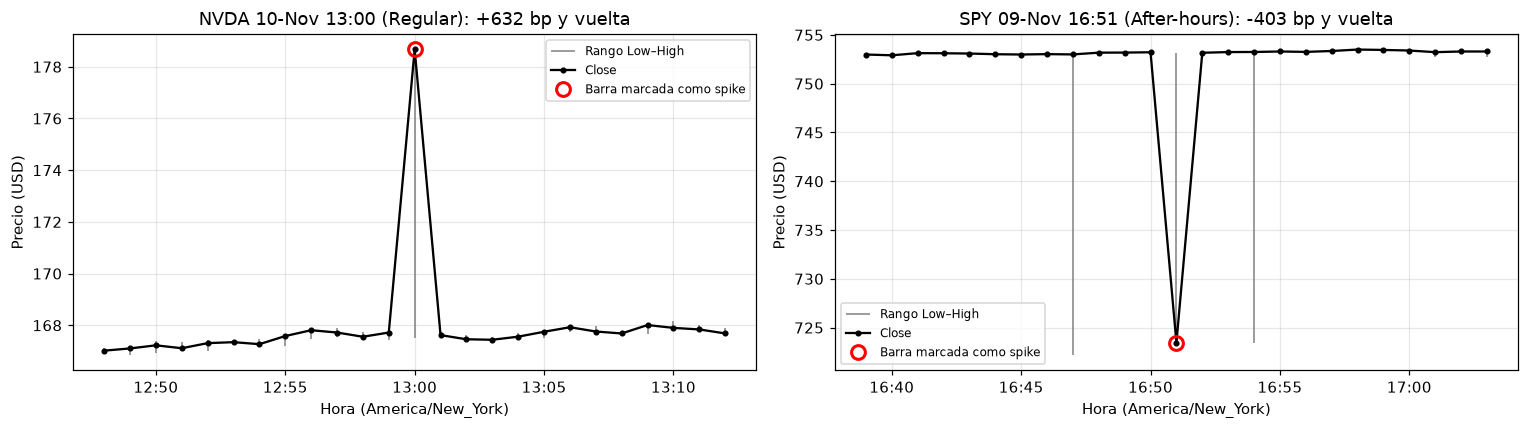

In [5]:
peores = spikes.reindex(spikes["r entrada (bp)"].abs().sort_values(ascending=False).index).head(2)
fig, axes = plt.subplots(1, len(peores), figsize=(14, 4))
for ax, (_, fila) in zip(np.atleast_1d(axes), peores.iterrows()):
    df = datos[fila["Ticker"]]
    ts = df.index[df.index.strftime("%d-%b %H:%M") == fila["Barra"]][0]
    w = df[(df.index >= ts - pd.Timedelta("12min")) & (df.index <= ts + pd.Timedelta("12min"))]
    x = w.index.tz_localize(None)
    ax.vlines(x, w["Low"], w["High"], color="grey", lw=1, label="Rango Low–High")
    ax.plot(x, w["Close"], "o-", ms=3, color="k", label="Close")
    ax.plot(ts.tz_localize(None), fila["Close spike"], "o", ms=9, mfc="none", mec="red", mew=2,
            label="Barra marcada como spike")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_title(f"{fila['Ticker']} {fila['Barra']} ({fila['Sesión']}): {fila['r entrada (bp)']:+.0f} bp y vuelta")
    ax.set_xlabel("Hora (America/New_York)")
    ax.set_ylabel("Precio (USD)")
    ax.legend(fontsize=8)
fig.tight_layout()
guardar(fig, "01_bad_ticks_detectados")
plt.show()

## 4. Estadísticas descriptivas por sesión — período pre-evento

Para cada sesión se calculan:

- **Volatilidad** $\hat\sigma$ de 1 minuto, en puntos básicos (bp).
- **Asimetría** $\hat\gamma_1$.
- **Curtosis en exceso** (de Fisher) $\hat\kappa = \hat m_4/\hat m_2^2 - 3$. Una gaussiana tiene
  $\kappa = 0$. Su error estándar aproximado bajo normalidad es $\sqrt{24/n}$.
- **Test de Jarque–Bera** de normalidad.
- **Exceso de colas 4σ:** número de $|z| > 4$ observados frente a los esperados bajo una gaussiana,
  $n \cdot 2\Phi(-4) \approx n \cdot 6.3\times10^{-5}$. Es más fácil de interpretar que la curtosis
  y menos dominado por un único valor extremo.

Esta tabla describe **solo el período pre-evento** y usa los retornos **limpios**, que son los que
alimentarán la calibración.

In [6]:
def describir(r: pd.Series) -> dict:
    r = r.dropna()
    n = len(r)
    z = (r - r.mean()) / r.std()
    jb = stats.jarque_bera(r)
    esperado4 = n * 2 * stats.norm.sf(4)
    return {"n": n, "media (bp)": 1e4 * r.mean(), "σ (bp)": 1e4 * r.std(),
            "asimetría": stats.skew(r), "curtosis exc.": stats.kurtosis(r),
            "EE curtosis": np.sqrt(24 / n), "JB p-valor": jb.pvalue,
            "|z|>4 obs": int((z.abs() > 4).sum()), "|z|>4 esp": esperado4,
            "mín (bp)": 1e4 * r.min(), "máx (bp)": 1e4 * r.max()}

def tabla_por_sesion(periodo: str) -> pd.DataFrame:
    filas = []
    for t in TICKERS:
        r = ret[t][ret[t]["Periodo"] == periodo]
        for s in SESIONES + ["Todas"]:
            sub = r["r"] if s == "Todas" else r.loc[r["Sesion"] == s, "r"]
            if len(sub) > 10:
                filas.append({"Ticker": t, "Sesión": s, **describir(sub)})
    return pd.DataFrame(filas).set_index(["Ticker", "Sesión"])

desc_pre = tabla_por_sesion("Pre-evento")
desc_pre.style.format(precision=3).format({"n": "{:,.0f}", "JB p-valor": "{:.1e}",
                                           "|z|>4 obs": "{:,.0f}", "|z|>4 esp": "{:.2f}"})

Como comparación, la misma tabla para los períodos **evento** y **post-evento**. El evento
contiene muy pocos días, así que estos números son solo descriptivos.

In [7]:
for periodo in ["Evento", "Post-evento"]:
    print(f"\n=== {periodo} ===")
    display(tabla_por_sesion(periodo)[["n", "σ (bp)", "asimetría", "curtosis exc.",
                                       "|z|>4 obs", "|z|>4 esp", "mín (bp)", "máx (bp)"]].round(3))


=== Evento ===


n  σ (bp)  asimetría  curtosis exc.  |z|>4 obs  \
Ticker Sesión                                                           
NVDA   Pre-market    329  22.044     -0.163          9.131          4   
       Regular       390  27.404      2.894         26.925          4   
       After-hours   481  33.486     -9.068        147.366          2   
       Todas        1200    28.8     -4.922        117.274          9   
SPY    Pre-market    264   2.359     -0.342          4.378          1   
       Regular       389   3.589      0.547          2.824          1   
       After-hours   436   2.186     -0.399          3.853          5   
       Todas        1089   2.802      0.321          4.552          5   

                    |z|>4 esp  mín (bp)  máx (bp)  
Ticker Sesión                                      
NVDA   Pre-market       0.021  -126.285    119.16  
       Regular          0.025  -115.231   273.898  
       After-hours       0.03  -547.801   148.452  
       Todas            0.076  -547.801   273.898  
SPY    Pre-market       0.017   -11.926     9.122  
       Regular          0.025   -12.413    19.567  
       After-hours      0.028   -10.172     9.374  
       Todas            0.069   -12.413    19.567


=== Post-evento ===


n  σ (bp)  asimetría  curtosis exc.  |z|>4 obs  \
Ticker Sesión                                                          
NVDA   Pre-market   329   12.54     -0.634          7.386          2   
       Regular      390  17.349      -2.31         17.765          2   
       After-hours  240   7.603      0.942          6.261          2   
       Todas        959  13.823     -2.022         20.887          7   
SPY    Pre-market   264   2.349      0.638          8.707          3   
       Regular      389   4.642     -0.255          2.302          2   
       After-hours  236   2.838     -0.173           2.62          1   
       Todas        889   3.635     -0.245          4.354          4   

                    |z|>4 esp  mín (bp)  máx (bp)  
Ticker Sesión                                      
NVDA   Pre-market       0.021   -84.937    52.285  
       Regular          0.025  -156.942    55.219  
       After-hours      0.015   -31.568    44.538  
       Todas            0.061  -156.942    55.219  
SPY    Pre-market       0.017    -12.42    13.214  
       Regular          0.025   -19.832    17.055  
       After-hours      0.015   -12.072     8.525  
       Todas            0.056   -19.832    17.055

## 5. Histogramas de retornos por sesión

Los retornos se estandarizan dentro de cada (ticker, sesión) y se comparan con una $\mathcal N(0,1)$.
El eje vertical está en **escala logarítmica**: en escala lineal todas las distribuciones con
pico alto parecen "normales", y las colas, que son lo que interesa, quedan invisibles. Una
gaussiana en escala log es una parábola; si hay colas gruesas, el histograma queda **por
encima** de ella en los extremos.

Debajo se agregan los **QQ-plots** contra la normal. Si las colas son gruesas, los puntos
extremos se separan de la diagonal en forma de "S".

Figura guardada: notebooks\figures\01_hist_retornos_por_sesion_pre_evento.png


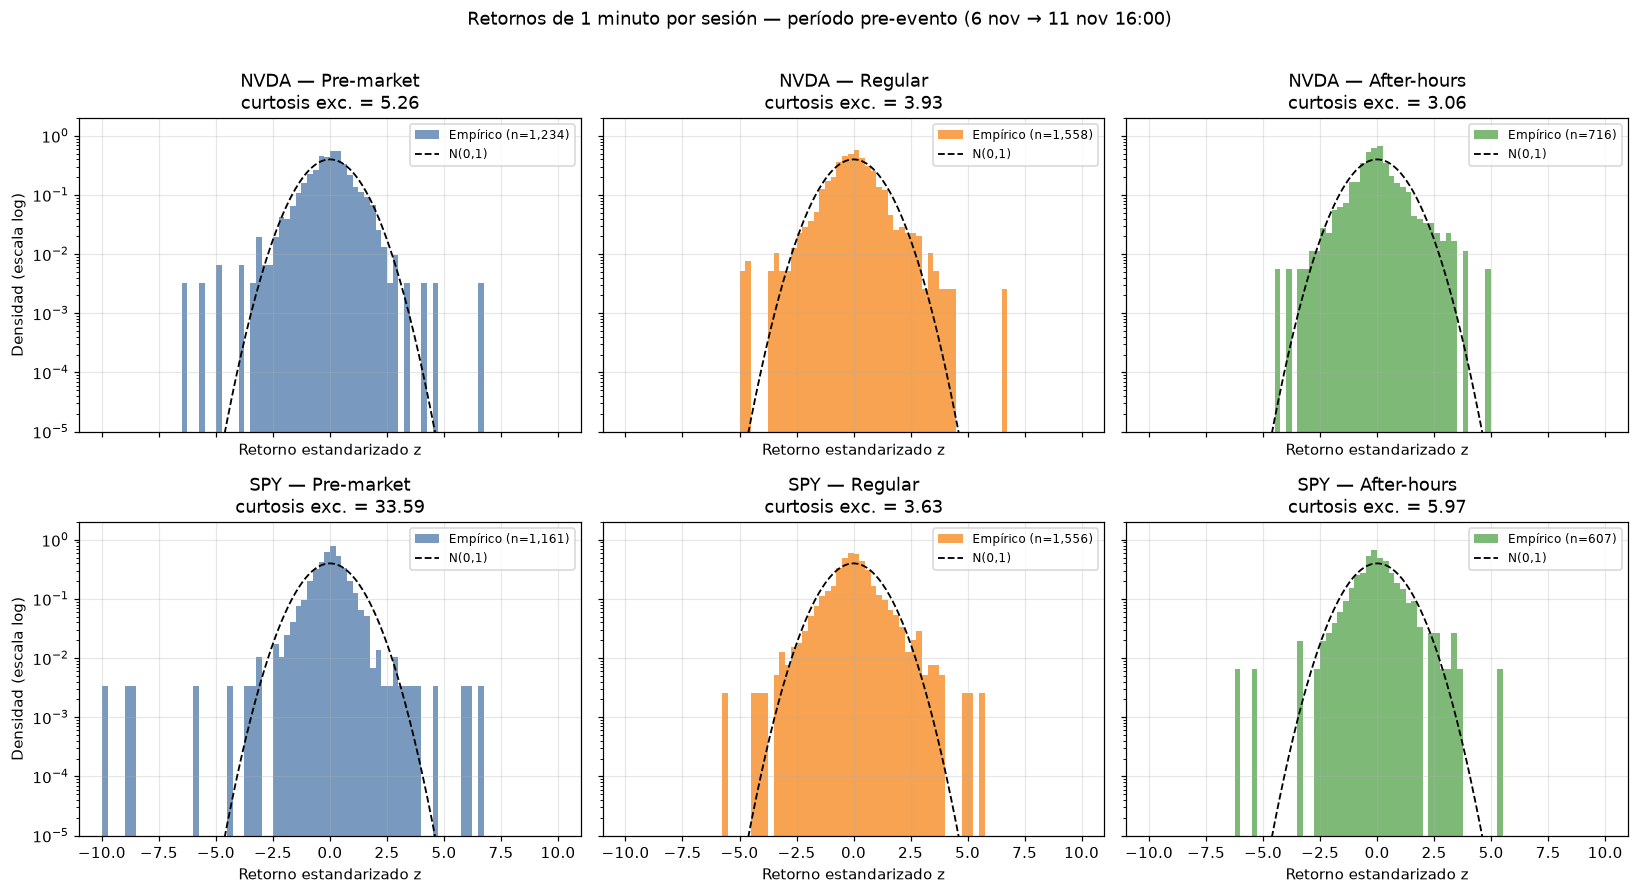

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
x = np.linspace(-10, 10, 400)
bins = np.linspace(-10, 10, 81)
for i, t in enumerate(TICKERS):
    r = ret[t][ret[t]["Periodo"] == "Pre-evento"]
    for j, s in enumerate(SESIONES):
        ax = axes[i, j]
        v = r.loc[r["Sesion"] == s, "r"]
        z = (v - v.mean()) / v.std()
        ax.hist(z.clip(-10, 10), bins=bins, density=True, color=COLORES[s], alpha=0.75,
                label=f"Empírico (n={len(z):,})")
        ax.plot(x, stats.norm.pdf(x), "k--", lw=1.2, label="N(0,1)")
        ax.set_yscale("log")
        ax.set_ylim(1e-5, 2)
        ax.set_title(f"{t} — {s}\ncurtosis exc. = {stats.kurtosis(v):.2f}")
        ax.set_xlabel("Retorno estandarizado z")
        if j == 0:
            ax.set_ylabel("Densidad (escala log)")
        ax.legend(fontsize=8, loc="upper right")
fig.suptitle("Retornos de 1 minuto por sesión — período pre-evento (6 nov → 11 nov 16:00)", y=1.01)
fig.tight_layout()
guardar(fig, "01_hist_retornos_por_sesion_pre_evento")
plt.show()

Figura guardada: notebooks\figures\01_qqplot_por_sesion_pre_evento.png


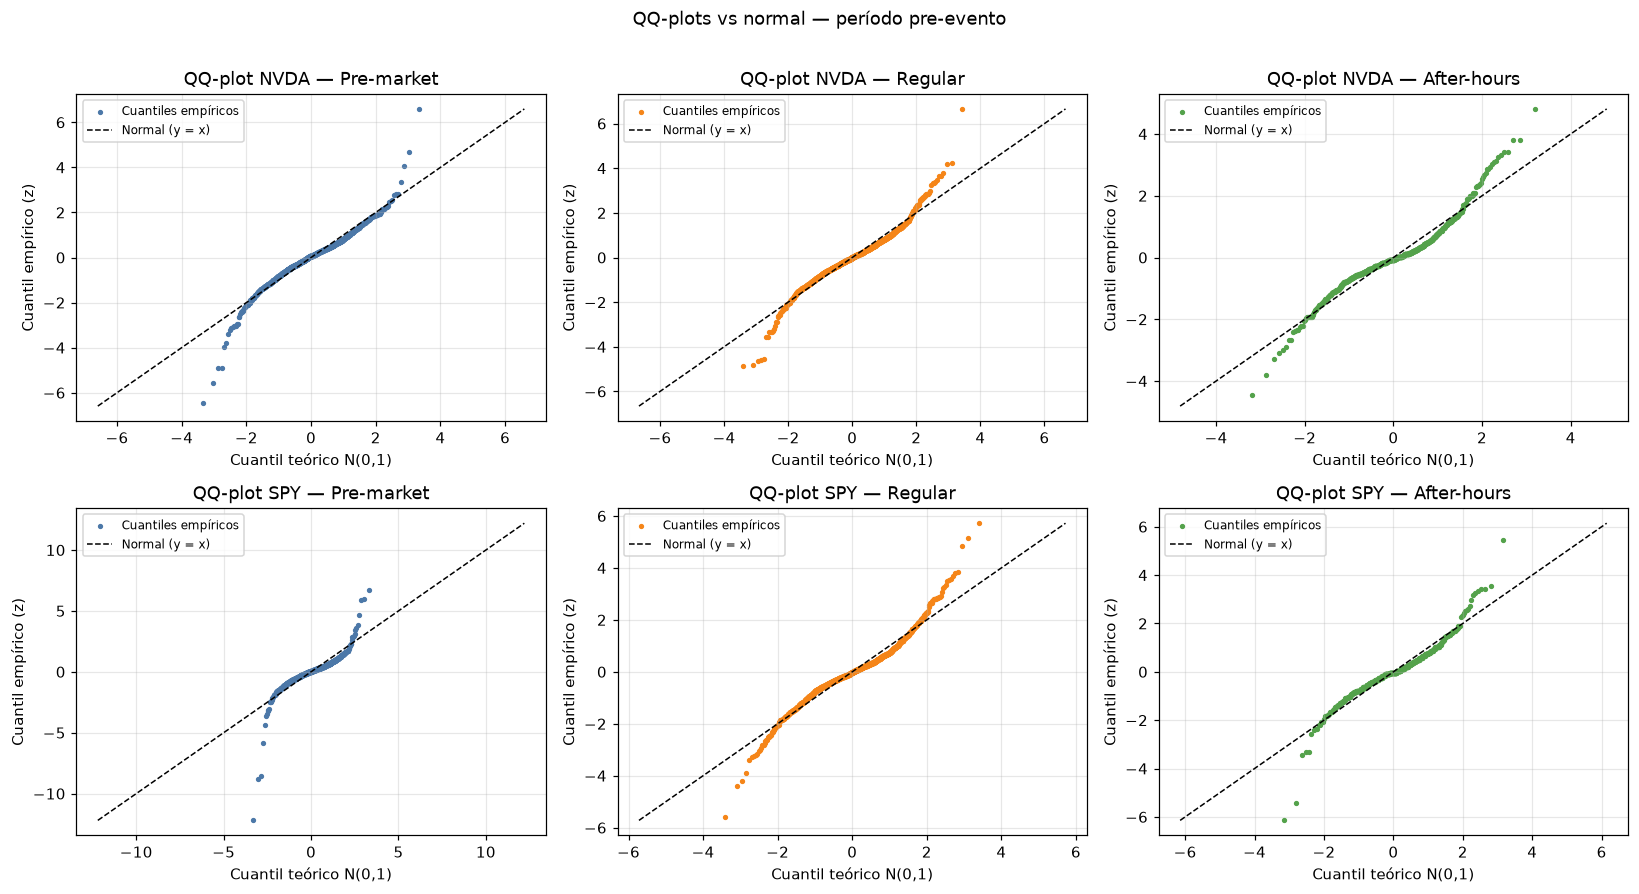

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, t in enumerate(TICKERS):
    r = ret[t][ret[t]["Periodo"] == "Pre-evento"]
    for j, s in enumerate(SESIONES):
        ax = axes[i, j]
        v = r.loc[r["Sesion"] == s, "r"]
        z = np.sort(((v - v.mean()) / v.std()).to_numpy())
        q = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
        ax.scatter(q, z, s=6, color=COLORES[s], label="Cuantiles empíricos")
        lim = max(abs(z).max(), 4.5)
        ax.plot([-lim, lim], [-lim, lim], "k--", lw=1, label="Normal (y = x)")
        ax.set_title(f"QQ-plot {t} — {s}")
        ax.set_xlabel("Cuantil teórico N(0,1)")
        ax.set_ylabel("Cuantil empírico (z)")
        ax.legend(fontsize=8, loc="upper left")
fig.suptitle("QQ-plots vs normal — período pre-evento", y=1.01)
fig.tight_layout()
guardar(fig, "01_qqplot_por_sesion_pre_evento")
plt.show()

## 6. Curtosis por día y por sesión

La curtosis agregada de varios días puede engañar. Si la volatilidad cambia de un día a otro, la
**mezcla** de gaussianas con distinta $\sigma$ ya es leptocúrtica:

$$ \kappa_{\text{mezcla}} = 3\,\frac{\operatorname{Var}(\sigma^2)}{\mathbb E[\sigma^2]^2} > 0 . $$

Por eso se distinguen dos fuentes de colas gruesas:

- **Heterocedasticidad entre bloques:** la volatilidad cambia entre días o sesiones, pero dentro de
  cada bloque los retornos son aproximadamente gaussianos. Un GBM con $\sigma$ variable lo explica.
- **Colas gruesas intrínsecas:** la curtosis persiste **dentro** de cada día y sesión. Esto es lo
  que el término de órdenes de Paolinelli–Arioli busca capturar.

La tabla día × sesión muestra la curtosis de cada bloque. Con $n \approx 390$, el error estándar
es $\approx 0.25$, así que valores mayores que $\sim 1$ ya son significativos.

In [10]:
filas = []
for t in TICKERS:
    r = ret[t]
    for (f, s), g in r.groupby(["Fecha", "Sesion"]):
        if s in SESIONES and len(g) > 30:
            filas.append({"Ticker": t, "Fecha": f, "Sesión": s, "n": len(g),
                          "curtosis exc.": stats.kurtosis(g["r"]), "σ (bp)": 1e4 * g["r"].std(),
                          "Periodo": g["Periodo"].mode().iat[0]})
kd = pd.DataFrame(filas)
piv = kd.pivot_table(index=["Ticker", "Fecha"], columns="Sesión", values="curtosis exc.")[SESIONES]
piv.style.format(precision=2).background_gradient(cmap="Reds", axis=None, vmin=0, vmax=20)

Figura guardada: notebooks\figures\01_curtosis_por_dia_y_sesion.png


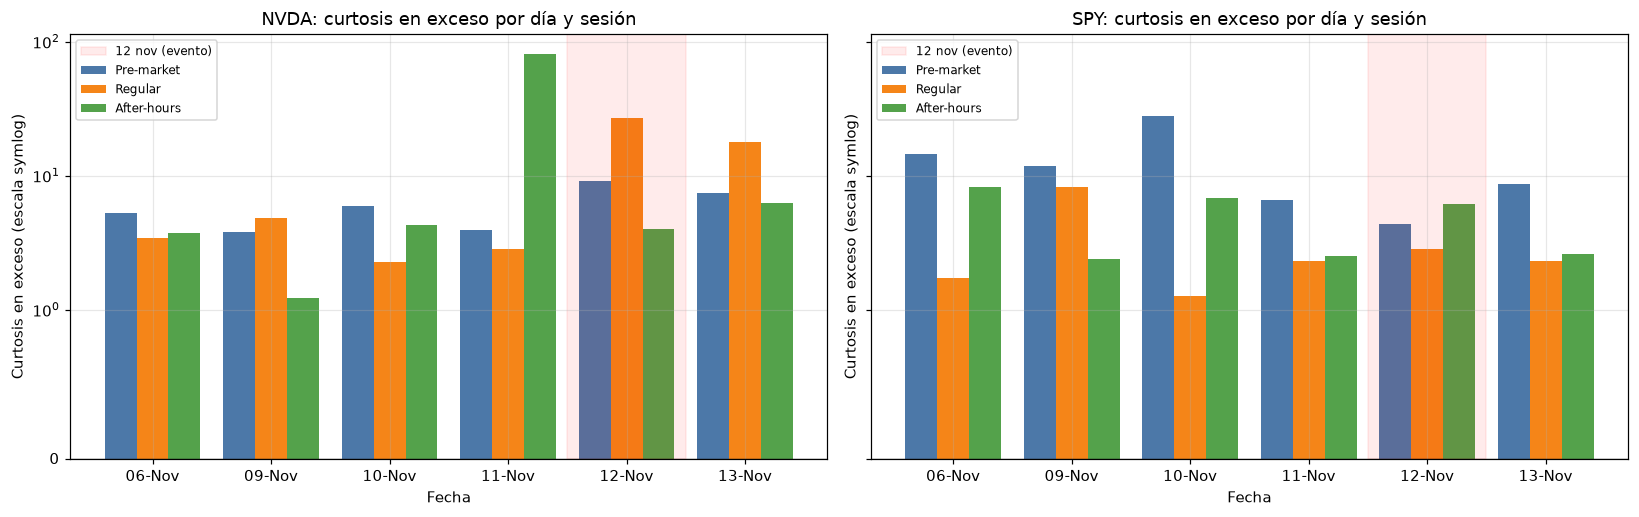

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, t in zip(axes, TICKERS):
    sub = kd[kd["Ticker"] == t]
    fechas = sorted(sub["Fecha"].unique())
    ancho = 0.27
    for k, s in enumerate(SESIONES):
        vals = [sub.loc[(sub.Fecha == f) & (sub["Sesión"] == s), "curtosis exc."].squeeze()
                if ((sub.Fecha == f) & (sub["Sesión"] == s)).any() else np.nan for f in fechas]
        ax.bar(np.arange(len(fechas)) + (k - 1) * ancho, vals, ancho, color=COLORES[s], label=s)
    ax.axhline(0, color="k", lw=0.8)
    ax.axvspan(fechas.index(FECHA_EVENTO) - 0.5, fechas.index(FECHA_EVENTO) + 0.5,
               color="red", alpha=0.08, label="12 nov (evento)")
    ax.set_xticks(range(len(fechas)), [f.strftime("%d-%b") for f in fechas])
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(f"{t}: curtosis en exceso por día y sesión")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Curtosis en exceso (escala symlog)")
    ax.legend(fontsize=8)
fig.tight_layout()
guardar(fig, "01_curtosis_por_dia_y_sesion")
plt.show()

### Descomposición: ¿cuánta curtosis sobrevive al normalizar la volatilidad?

Para cada ticker se calcula la curtosis del período pre-evento de cuatro formas:

0. **Con spikes:** sin aplicar el control de calidad de la sección 3.1, solo como referencia.
1. **Bruta:** todos los retornos limpios juntos.
2. **Normalizada por (día, sesión):** cada retorno se divide por la $\sigma$ de su bloque. Esto
   elimina la mezcla de volatilidades entre bloques.
3. **Normalizada por (día, sesión) y sin ceros:** además se excluyen los retornos exactamente cero,
   que son precios congelados por falta de liquidez.

Para medir la incertidumbre se calcula un **intervalo bootstrap al 95 %** con remuestreo por bloques
de 30 minutos, que respeta la dependencia temporal (clustering de volatilidad). Si la curtosis
normalizada sigue siendo claramente mayor que 0, hay colas gruesas **dentro** de los bloques.

In [12]:
def bootstrap_curtosis(x: np.ndarray, bloque: int = 30, B: int = 2000) -> tuple[float, float]:
    n = len(x)
    nb = int(np.ceil(n / bloque))
    starts = RNG.integers(0, n - bloque + 1, size=(B, nb))
    idx = (starts[:, :, None] + np.arange(bloque)).reshape(B, -1)[:, :n]
    k = stats.kurtosis(x[idx], axis=1)
    return tuple(np.percentile(k, [2.5, 97.5]))

filas = []
for t in TICKERS:
    r = ret[t][ret[t]["Periodo"] == "Pre-evento"].copy()
    r["z_bloque"] = r.groupby(["Fecha", "Sesion"])["r"].transform(lambda v: (v - v.mean()) / v.std())
    rb = ret_bruto[t][ret_bruto[t]["Periodo"] == "Pre-evento"]
    for s in SESIONES + ["Todas"]:
        sub = r if s == "Todas" else r[r["Sesion"] == s]
        sub_b = rb if s == "Todas" else rb[rb["Sesion"] == s]
        variantes = {"0. Con spikes": sub_b["r"].to_numpy(),
                     "1. Bruta": sub["r"].to_numpy(),
                     "2. Norm. (día, sesión)": sub["z_bloque"].to_numpy(),
                     "3. Norm. sin ceros": sub.loc[sub["r"] != 0, "z_bloque"].to_numpy()}
        for nombre, v in variantes.items():
            lo, hi = bootstrap_curtosis(v)
            filas.append({"Ticker": t, "Sesión": s, "Variante": nombre, "n": len(v),
                          "curtosis exc.": stats.kurtosis(v), "IC95 inf": lo, "IC95 sup": hi})
descomp = pd.DataFrame(filas).set_index(["Ticker", "Sesión", "Variante"])
descomp.style.format(precision=2).format({"n": "{:,.0f}"})

## 7. Precio intradía del 6 al 13 de noviembre

El eje horizontal está **comprimido**: solo muestra los minutos con datos (de 04:00 a 20:00), sin
noches ni fin de semana. El horario extendido aparece sombreado. Se marcan:

- **Línea negra discontinua:** fin de la ventana de calibración (11 nov, 16:00).
- **Línea roja:** el minuto con el mayor $|r|$ entre el cierre del 11 y el final del 12, es decir,
  el salto detectado en los datos.
- **Banda roja:** el día del evento (12 nov).

Ambos tickers se muestran también normalizados a 100 al cierre regular del 11 de noviembre, para
comparar la magnitud del movimiento.

> El gráfico muestra los precios **sin limpiar**. Los *bad ticks* de la sección 3.1 se ven como
> "agujas" verticales: NVDA el 10-nov a las 13:00 y SPY el 09-nov a las 16:51.

Figura guardada: notebooks\figures\01_precio_intradia_6_13_nov.png


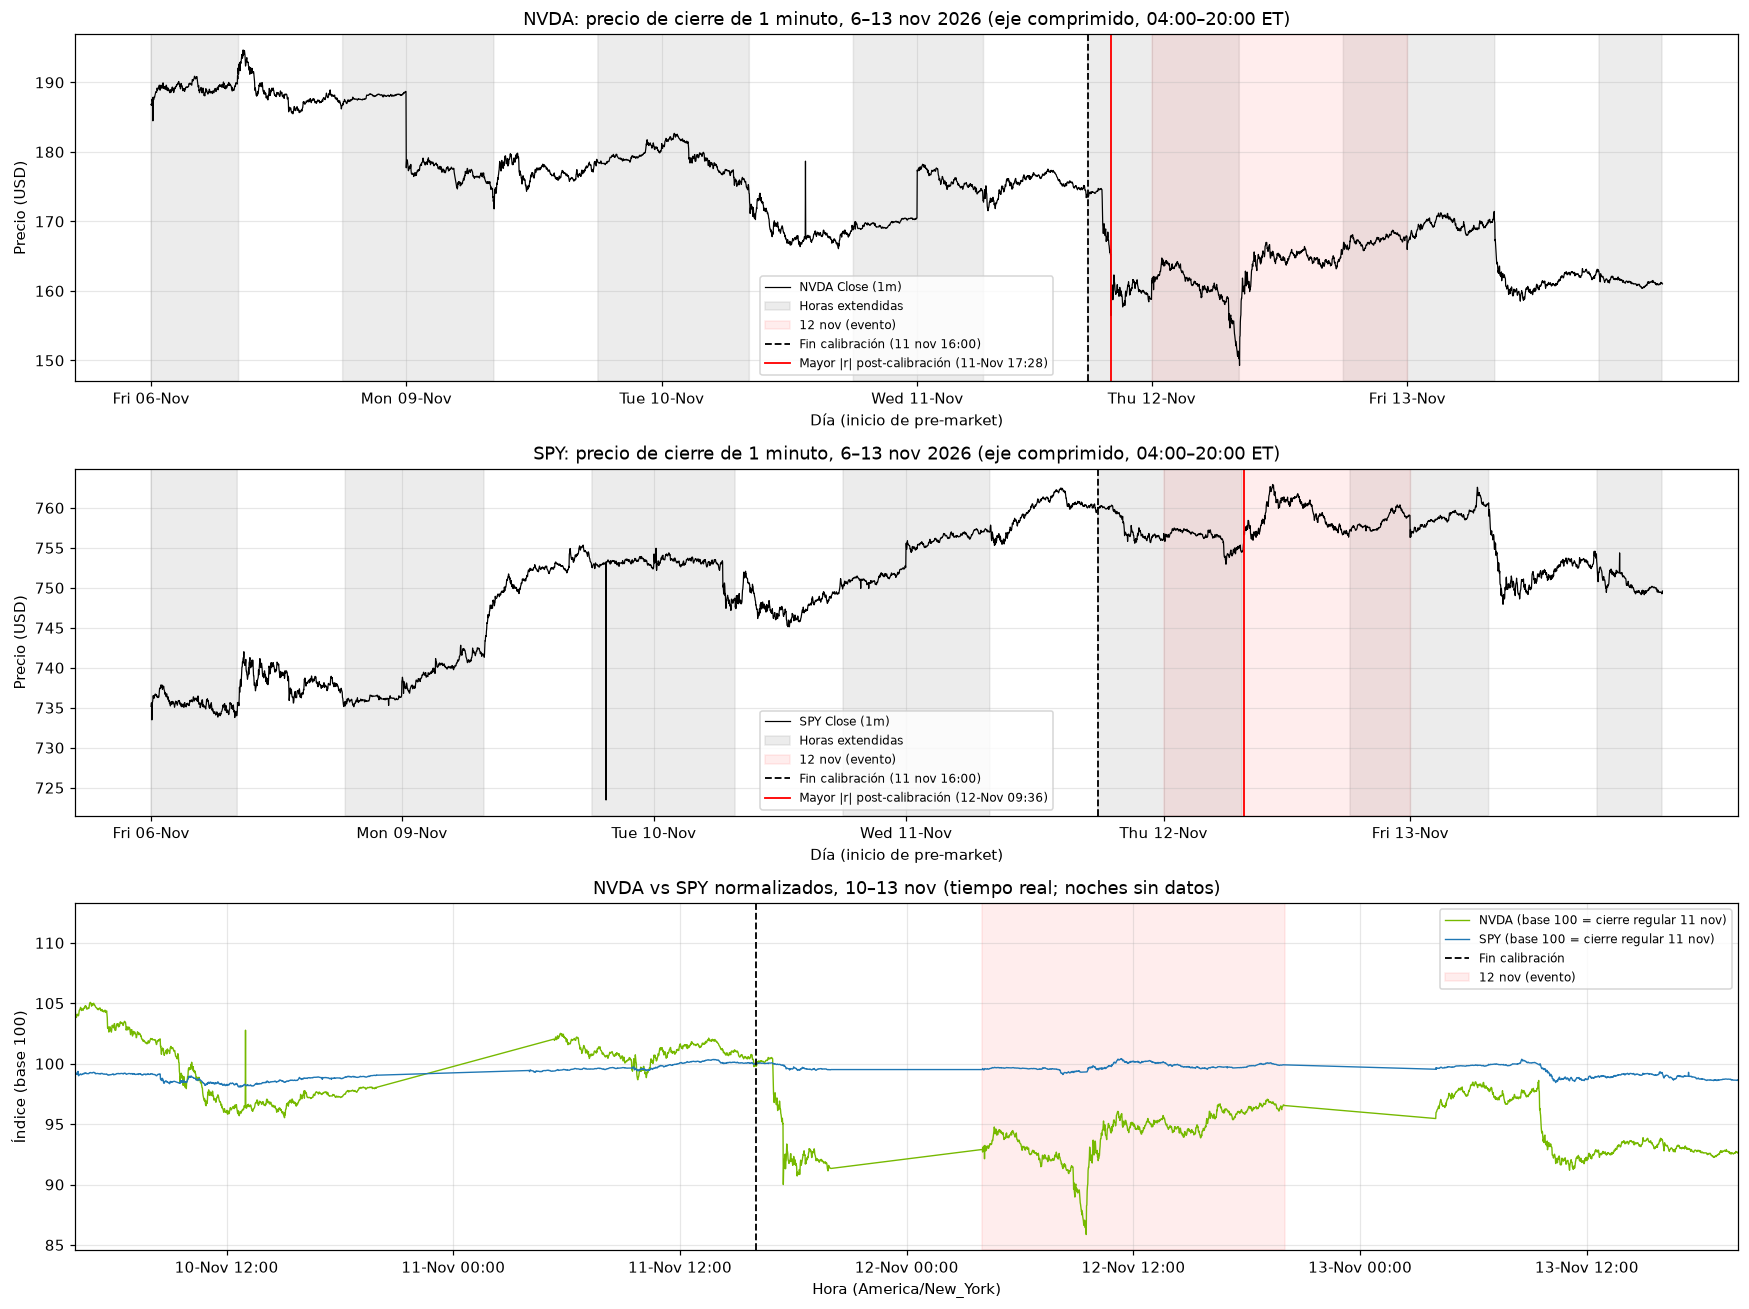

In [13]:
def precio_cierre_regular(df: pd.DataFrame, fecha: date) -> float:
    g = df[(df["Fecha"] == fecha) & (df["Sesion"] == "Regular")]
    return float(g["Close"].iloc[-1])

ventana_salto = {t: ret[t][(ret[t].index >= FIN_CALIBRACION) & (ret[t].index < FIN_EVENTO)]
                 for t in TICKERS}
salto = {t: ventana_salto[t]["r"].abs().idxmax() for t in TICKERS}

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=False,
                         gridspec_kw={"height_ratios": [1, 1, 1]})
for ax, t in zip(axes[:2], TICKERS):
    df = datos[t][datos[t]["Sesion"] != "Fuera de sesión"]
    pos = np.arange(len(df))
    ax.plot(pos, df["Close"].to_numpy(), lw=0.8, color="k", label=f"{t} Close (1m)")
    ext = (df["Sesion"] != "Regular").to_numpy()
    ax.fill_between(pos, 0, 1, where=ext, transform=ax.get_xaxis_transform(),
                    color="grey", alpha=0.15, step="mid", label="Horas extendidas")
    ev = (df["Fecha"] == FECHA_EVENTO).to_numpy()
    ax.fill_between(pos, 0, 1, where=ev, transform=ax.get_xaxis_transform(),
                    color="red", alpha=0.07, step="mid", label="12 nov (evento)")
    ax.axvline(np.searchsorted(df.index, FIN_CALIBRACION), color="k", ls="--", lw=1.2,
               label="Fin calibración (11 nov 16:00)")
    ax.axvline(np.searchsorted(df.index, salto[t]), color="red", lw=1.2,
               label=f"Mayor |r| post-calibración ({salto[t]:%d-%b %H:%M})")
    inicio_dia = df.groupby("Fecha").apply(lambda g: np.searchsorted(df.index, g.index[0]))
    ax.set_xticks(inicio_dia.to_numpy(), [f"{d:%a %d-%b}" for d in inicio_dia.index])
    ax.set_title(f"{t}: precio de cierre de 1 minuto, 6–13 nov 2026 (eje comprimido, 04:00–20:00 ET)")
    ax.set_xlabel("Día (inicio de pre-market)")
    ax.set_ylabel("Precio (USD)")
    ax.legend(fontsize=8, loc="best")

ax = axes[2]
for t, c in zip(TICKERS, ["#76B900", "#1f77b4"]):
    df = datos[t][datos[t]["Sesion"] != "Fuera de sesión"]
    base = precio_cierre_regular(datos[t], date(2026, 11, 11))
    ax.plot(df.index.tz_localize(None), 100 * df["Close"] / base, lw=0.9, color=c,
            label=f"{t} (base 100 = cierre regular 11 nov)")
ax.axvline(FIN_CALIBRACION.tz_localize(None), color="k", ls="--", lw=1.2, label="Fin calibración")
ax.axvspan(datetime(2026, 11, 12, 4), datetime(2026, 11, 12, 20), color="red", alpha=0.07,
           label="12 nov (evento)")
ax.set_xlim(datetime(2026, 11, 10, 4), datetime(2026, 11, 13, 20))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b %H:%M"))
ax.set_title("NVDA vs SPY normalizados, 10–13 nov (tiempo real; noches sin datos)")
ax.set_xlabel("Hora (America/New_York)")
ax.set_ylabel("Índice (base 100)")
ax.legend(fontsize=8)
fig.tight_layout()
guardar(fig, "01_precio_intradia_6_13_nov")
plt.show()

## 8. Cronología del evento según los datos

El planteamiento del proyecto dice que el anuncio fue **antes de la apertura del 12 de noviembre**.
Antes de definir los retornos del test (notebook 04), se verifica en los datos **cuándo** empieza
realmente el movimiento. Para eso se reportan:

- Los precios en los instantes clave.
- Los diez minutos con mayor $|r|$ entre el cierre regular del 11 y el final del 12, cada uno con
  su z-score respecto a la $\sigma$ pre-evento de su propia sesión.

> Este notebook **no** calcula todavía las probabilidades del test. Solo describe los datos.

### 8.1 Gaps entre sesiones en toda la ventana

El retorno "overnight" del test (cierre regular → apertura regular siguiente) **no es un retorno
de 1 minuto**. Abarca unas 17,5 horas de reloj, incluidas 4 horas de after-hours y 5,5 de
pre-market. Antes del test conviene ver cómo se comportaron esos gaps **en los días previos al
evento**.

En la tabla, cada fila muestra el retorno desde el cierre regular del día indicado hasta la
apertura regular del siguiente día hábil, descompuesto en sus tramos.

In [14]:
filas = []
for t in TICKERS:
    df = datos[t][datos[t]["Sesion"] != "Fuera de sesión"]
    fechas = sorted(df["Fecha"].unique())
    for f0, f1 in zip(fechas[:-1], fechas[1:]):
        d0, d1 = df[df["Fecha"] == f0], df[df["Fecha"] == f1]
        c_reg = d0.loc[d0["Sesion"] == "Regular", "Close"].iloc[-1]
        c_ah = d0["Close"].iloc[-1]
        p_pre = d1["Close"].iloc[0]
        o_reg = d1.loc[d1["Sesion"] == "Regular", "Open"].iloc[0]
        filas.append({"Ticker": t, "Desde (cierre)": f0, "Hasta (apertura)": f1,
                      "After-hours (%)": 100 * np.log(c_ah / c_reg),
                      "Noche AH→pre (%)": 100 * np.log(p_pre / c_ah),
                      "Pre-market (%)": 100 * np.log(o_reg / p_pre),
                      "Total cierre→apertura (%)": 100 * np.log(o_reg / c_reg),
                      "Ventana": "Evento" if f0 == date(2026, 11, 11) else
                                 ("Pre-evento" if f1 <= date(2026, 11, 11) else "Post-evento")})
gaps = pd.DataFrame(filas).set_index(["Ticker", "Desde (cierre)"])
gaps.style.format(precision=2).background_gradient(
    cmap="RdBu", subset=["Total cierre→apertura (%)"], vmin=-15, vmax=15)

In [15]:
def precio_en(df: pd.DataFrame, ts: str, col: str = "Close") -> tuple[pd.Timestamp, float]:
    t0 = pd.Timestamp(ts, tz=NY_TZ)
    sub = df[df.index >= t0]
    return (sub.index[0], float(sub[col].iloc[0])) if len(sub) else (pd.NaT, np.nan)

def ultimo_antes(df: pd.DataFrame, ts: str) -> tuple[pd.Timestamp, float]:
    t0 = pd.Timestamp(ts, tz=NY_TZ)
    sub = df[df.index < t0]
    return sub.index[-1], float(sub["Close"].iloc[-1])

hitos = []
for t in TICKERS:
    df = datos[t][datos[t]["Sesion"] != "Fuera de sesión"]
    p = {
        "Cierre regular 11-nov (15:59)": ultimo_antes(df, "2026-11-11 16:00"),
        "Último after-hours 11-nov": ultimo_antes(df, "2026-11-12 00:00"),
        "Primer pre-market 12-nov": precio_en(df, "2026-11-12 04:00"),
        "Último pre-market 12-nov (09:29)": ultimo_antes(df, "2026-11-12 09:30"),
        "Apertura regular 12-nov (09:30, Open)": precio_en(df, "2026-11-12 09:30", "Open"),
        "Cierre regular 12-nov (15:59)": ultimo_antes(df, "2026-11-12 16:00"),
    }
    base = p["Cierre regular 11-nov (15:59)"][1]
    for k, (ts, px) in p.items():
        hitos.append({"Ticker": t, "Hito": k, "Hora": ts.strftime("%d-%b %H:%M"), "Precio": px,
                      "Ret. log vs cierre 11-nov (%)": 100 * np.log(px / base)})
pd.DataFrame(hitos).set_index(["Ticker", "Hito"]).style.format(
    {"Precio": "{:.2f}", "Ret. log vs cierre 11-nov (%)": "{:+.2f}"})

In [16]:
sig_pre = {t: ret[t][ret[t]["Periodo"] == "Pre-evento"].groupby("Sesion")["r"].std() for t in TICKERS}
for t in TICKERS:
    v = ventana_salto[t].copy()
    v["z vs σ pre-evento de su sesión"] = v["r"] / v["Sesion"].map(sig_pre[t])
    top = v.reindex(v["r"].abs().sort_values(ascending=False).index).head(10)
    top = top.assign(**{"r (%)": 100 * top["r"]})[["Sesion", "r (%)", "z vs σ pre-evento de su sesión"]]
    top.index = top.index.strftime("%d-%b %H:%M")
    print(f"\n{t}: 10 mayores |r| de 1 minuto entre 11-nov 16:00 y 12-nov 20:00")
    display(top.round(2))


NVDA: 10 mayores |r| de 1 minuto entre 11-nov 16:00 y 12-nov 20:00


,Sesion,r (%),z vs σ pre-evento de su sesión
Datetime,,,
11-Nov 17:28,After-hours,-5.48,-96.27
12-Nov 09:31,Regular,2.74,17.97
11-Nov 17:29,After-hours,1.48,26.09
11-Nov 17:35,After-hours,-1.33,-23.32
12-Nov 09:33,Regular,1.32,8.64
12-Nov 08:50,Pre-market,-1.26,-10.01
12-Nov 09:36,Regular,1.25,8.19
12-Nov 04:08,Pre-market,1.19,9.45
11-Nov 16:56,After-hours,-1.19,-20.92



SPY: 10 mayores |r| de 1 minuto entre 11-nov 16:00 y 12-nov 20:00


,Sesion,r (%),z vs σ pre-evento de su sesión
Datetime,,,
12-Nov 09:36,Regular,0.2,5.17
12-Nov 10:51,Regular,0.14,3.71
12-Nov 10:00,Regular,-0.12,-3.28
12-Nov 08:09,Pre-market,-0.12,-3.49
12-Nov 10:11,Regular,0.12,3.11
11-Nov 17:37,After-hours,-0.1,-5.72
12-Nov 10:21,Regular,0.1,2.62
12-Nov 10:57,Regular,0.1,2.57
12-Nov 10:20,Regular,-0.1,-2.55


## 9. Conclusión

> Las cifras citadas corresponden a la ejecución con los datos actuales de `data/raw/yahoo_1m/`
> (6–13 nov 2026). Si los CSV cambian, revisa las tablas de arriba.

### ¿NVDA ya mostraba colas gruesas antes del evento?

**Sí, pero no eran específicas de NVDA.**

1. **Las colas gruesas están presentes y son significativas.** En el período pre-evento, con los
   datos limpios, la curtosis en exceso de NVDA es ≈ 5,3 en pre-market, 3,9 en la sesión regular y
   3,1 en after-hours. Todos los intervalos bootstrap por bloques excluyen el 0. Hay **21 retornos
   con |z| > 4**, cuando una gaussiana esperaría unos **0,2**.

2. **No son solo un efecto de mezcla de volatilidades.** Si se normaliza cada bloque (día, sesión)
   por su propia σ, la curtosis conjunta de NVDA baja de 5,8 a ≈ 3,8 (IC95 ≈ [2,6; 5,0]). Por lo
   tanto, hay colas gruesas **dentro** de cada bloque, que es justo el ingrediente que el término
   de órdenes ($\alpha_1, \alpha_2$) de Paolinelli–Arioli necesita para no colapsar al GBM.

3. **SPY, el control, muestra la misma forma de cola.** En la sesión regular, la curtosis de SPY
   es ≈ 3,6 y la de NVDA ≈ 3,9, con intervalos solapados. Las colas gruesas a 1 minuto son un
   **hecho estilizado genérico** de la microestructura, no una anomalía de NVDA. Lo que distingue
   a NVDA es el **nivel** de volatilidad (σ ≈ 15 bp/min frente a 3,8 bp/min de SPY en la sesión
   regular) y los **gaps entre sesiones**, no la forma de la distribución de 1 minuto.

4. **NVDA ya había tenido un gap de −8,3 % dentro de la ventana de calibración** (del cierre del
   6-nov a la apertura del 9-nov), además de gaps de −2,6 % y +2,3 %. Los gaps de SPY en las mismas
   noches no superan el ±1 %. El salto del evento (−15,2 % de cierre a apertura) es unas dos veces
   el mayor gap previo, no un movimiento sin precedentes en la ventana. Sin embargo, estos gaps
   **no forman parte** de la distribución de retornos de 1 minuto: por construcción no se cruzan
   días.

### Hallazgos sobre los datos que afectan a los pasos siguientes

- ***Bad ticks.*** Hay dos impresiones erróneas evidentes (NVDA el 10-nov a las 13:00 con +6,3 % y
  vuelta, y SPY el 09-nov a las 16:51 con −4,0 % y vuelta) y otras cinco menores. Sin limpieza,
  la curtosis pre-evento sería **538 en NVDA y 1325 en SPY**, valores que no tienen ningún
  significado físico. **La calibración del notebook 03 debe usar los retornos limpios**; si no,
  $\alpha_1$ y $\alpha_2$ terminarían ajustando errores de Yahoo.
- **Cronología del evento.** Los datos **no** coinciden con un anuncio pre-apertura del 12. El
  movimiento empieza en el **after-hours del 11-nov**:

  | Momento | Movimiento |
  |---|---|
  | 16:56 | −1,2 % |
  | 17:28 | **−5,5 % en un solo minuto**, unas 96σ del after-hours pre-evento |
  | 20:00 (cierre del after-hours) | −9,1 % acumulado |
  | Pre-market del 12 | −7,9 % adicional |
  | Apertura del 12 | −15,2 % frente al cierre regular del 11 |

  SPY se movió solo −0,8 % en el mismo intervalo. El corte de calibración (11-nov, 16:00) queda
  **antes** del salto, así que la ventana de calibración **no está contaminada**. En cambio, el
  retorno "pre-market" del paso 3a (primer minuto del 12 → 09:30) solo captura la mitad del
  movimiento.
- **Horario extendido poco fiable.** El volumen es 0 en todas las barras, SPY tiene huecos (entre
  86 % y 95 % de cobertura) y su curtosis de pre-market (≈ 34) se debe a unas pocas impresiones en
  un mercado poco líquido. La sesión regular es la base más sólida para calibrar.

### Limitaciones

- **Muestra pequeña.** La ventana de calibración tiene unos 3,5 días y ≈ 3.500 retornos. El cuarto
  momento es muy inestable: los intervalos bootstrap son anchos y asimétricos.
- **No se eliminó la estacionalidad intradía.** La volatilidad tiene forma de U a lo largo del
  día, y eso aporta algo de curtosis a la sesión regular. Separarla requiere más días que los
  disponibles.
- **Horizonte del test.** El salto relevante es un gap de ~17,5 horas y no un retorno de 1 minuto.
  Cómo pasar de una distribución calibrada a 1 minuto a una predicción para ese horizonte es una
  decisión de diseño de los notebooks 02–04.